# Silkworm Disease Classification — MobileNetV2

This notebook trains a 5-class image classifier using your uploaded Mendeley dataset.

**Classes:** Healthy, Pebrine, Flacherie, Overlap, Grasserie  
**Model:** MobileNetV2 transfer learning  
**Input:** 224 × 224 RGB images  
**Outputs:** Keras model, TensorFlow Lite model, class labels, evaluation report and confusion matrix.

Run the cells from top to bottom in Google Colab. When prompted, upload `Mendeley_silkworm dataset splitting.zip`. The notebook keeps the dataset's existing Train / Val / Test split.


## 1. Install and import libraries

In [1]:
!pip -q install tensorflow scikit-learn matplotlib seaborn

import os
import json
import zipfile
import shutil
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)
print("Available GPU(s):", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPU(s): []


## 2. Upload and extract the dataset

In [7]:
import os
import zipfile

# Paste your exact file path inside the quotes
zip_path = "/content/Mendeley_silkworm dataset splitting.zip"
extract_path = "/content/silkworm_extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
  z.extractall(extract_path)

print("Extracted successfully to:", extract_path)

Extracted successfully to: /content/silkworm_extracted


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 3. Find the dataset and prepare Train / Val / Test folders

In [8]:

from pathlib import Path

EXTRACT_DIR = Path("/content/silkworm_extracted")

print("Dataset folder:", EXTRACT_DIR)
print("Folder exists:", EXTRACT_DIR.exists())


Dataset folder: /content/silkworm_extracted
Folder exists: True


In [9]:
# The ZIP contains one folder per class, with Train, Val and Test inside.
EXPECTED_CLASSES = ["Healthy", "Pebrine", "Flacherie", "Overlap", "grasserie"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

dataset_root = None
for candidate in [EXTRACT_DIR] + [p for p in EXTRACT_DIR.rglob("*") if p.is_dir()]:
    if all((candidate / cls).is_dir() for cls in EXPECTED_CLASSES):
        if all((candidate / cls / split).is_dir()
               for cls in EXPECTED_CLASSES
               for split in ["Train", "Val", "Test"]):
            dataset_root = candidate
            break

if dataset_root is None:
    raise FileNotFoundError(
        "Could not find the expected class/Train/Val/Test folder structure. "
        "Check that you uploaded the original dataset ZIP."
    )

print("Dataset root:", dataset_root)

# Create the directory layout expected by flow_from_directory:
# prepared/Train/Healthy, prepared/Val/Healthy, etc.
PREPARED_DIR = Path("/content/silkworm_prepared")
if PREPARED_DIR.exists():
    shutil.rmtree(PREPARED_DIR)

counts = {}
for split in ["Train", "Val", "Test"]:
    for cls in EXPECTED_CLASSES:
        src = dataset_root / cls / split
        dst = PREPARED_DIR / split / cls
        dst.mkdir(parents=True, exist_ok=True)

        image_files = [p for p in src.rglob("*")
                       if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
        for image_file in image_files:
            shutil.copy2(image_file, dst / image_file.name)

        counts[(split, cls)] = len(image_files)

for split in ["Train", "Val", "Test"]:
    print(f"\\n{split}:")
    for cls in EXPECTED_CLASSES:
        print(f"  {cls}: {counts[(split, cls)]} images")

if any(counts[(split, cls)] == 0
       for split in ["Train", "Val", "Test"]
       for cls in EXPECTED_CLASSES):
    raise ValueError("At least one class/split folder is empty. Check the dataset structure.")

Dataset root: /content/silkworm_extracted/Mendeley_silkworm dataset splitting
\nTrain:
  Healthy: 769 images
  Pebrine: 715 images
  Flacherie: 711 images
  Overlap: 885 images
  grasserie: 788 images
\nVal:
  Healthy: 111 images
  Pebrine: 103 images
  Flacherie: 102 images
  Overlap: 127 images
  grasserie: 114 images
\nTest:
  Healthy: 219 images
  Pebrine: 204 images
  Flacherie: 203 images
  Overlap: 253 images
  grasserie: 225 images


## 4. Load and preprocess images

In [10]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_data = train_datagen.flow_from_directory(
    PREPARED_DIR / "Train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)
val_data = eval_datagen.flow_from_directory(
    PREPARED_DIR / "Val",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)
test_data = eval_datagen.flow_from_directory(
    PREPARED_DIR / "Test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

class_names = [name for name, index in
               sorted(train_data.class_indices.items(), key=lambda item: item[1])]
print("Class mapping:", train_data.class_indices)
print("Classes in model order:", class_names)

Found 3868 images belonging to 5 classes.
Found 557 images belonging to 5 classes.
Found 1104 images belonging to 5 classes.
Class mapping: {'Flacherie': 0, 'Healthy': 1, 'Overlap': 2, 'Pebrine': 3, 'grasserie': 4}
Classes in model order: ['Flacherie', 'Healthy', 'Overlap', 'Pebrine', 'grasserie']


## 5. Build the MobileNetV2 model

In [11]:
# ImageNet weights are downloaded by TensorFlow on first run.
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
# training=False keeps pretrained Batch Normalization layers in inference mode.
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.35)(x)
outputs = Dense(len(class_names), activation="softmax")(x)

model = Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,205 (9.87 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Train the classification head

In [12]:
HEAD_MODEL_PATH = "/content/best_silkworm_head.keras"

head_callbacks = [
    ModelCheckpoint(HEAD_MODEL_PATH, monitor="val_loss",
                    save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2,
                     patience=2, min_lr=1e-7, verbose=1)
]

history_head = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=head_callbacks
)

model = tf.keras.models.load_model(HEAD_MODEL_PATH)

Epoch 1/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8205 - loss: 0.5276
Epoch 1: val_loss improved from None to 0.07186, saving model to /content/best_silkworm_head.keras

Epoch 1: finished saving model to /content/best_silkworm_head.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 320s 3s/step - accuracy: 0.9105 - loss: 0.2590 - val_accuracy: 0.9713 - val_loss: 0.0719 - learning_rate: 0.0010
Epoch 2/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9613 - loss: 0.1097
Epoch 2: val_loss improved from 0.07186 to 0.05209, saving model to /content/best_silkworm_head.keras

Epoch 2: finished saving model to /content/best_silkworm_head.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.9677 - loss: 0.0932 - val_accuracy: 0.9856 - val_loss: 0.0521 - learning_rate: 0.0010
Epoch 3/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9834 - loss: 0.0507
Epoch 3: val_loss did not improve from 0.05209
121/121 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.9770 - loss: 0.0636

## 7. Fine-tune the last MobileNetV2 layers

In [13]:
base_model.trainable = True

# Freeze earlier layers and fine-tune only the last 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for more stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

FINE_TUNED_PATH = "/content/best_silkworm_finetuned.keras"

fine_callbacks = [
    ModelCheckpoint(FINE_TUNED_PATH, monitor="val_loss",
                    save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2,
                     patience=2, min_lr=1e-7, verbose=1)
]

history_fine = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=fine_callbacks
)

model = tf.keras.models.load_model(FINE_TUNED_PATH)

Epoch 1/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9897 - loss: 0.0290
Epoch 1: val_loss improved from None to 0.04210, saving model to /content/best_silkworm_finetuned.keras

Epoch 1: finished saving model to /content/best_silkworm_finetuned.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 273s 2s/step - accuracy: 0.9907 - loss: 0.0285 - val_accuracy: 0.9856 - val_loss: 0.0421 - learning_rate: 1.0000e-05
Epoch 2/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9910 - loss: 0.0280
Epoch 2: val_loss did not improve from 0.04210
121/121 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.9917 - loss: 0.0252 - val_accuracy: 0.9856 - val_loss: 0.0429 - learning_rate: 1.0000e-05
Epoch 3/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9918 - loss: 0.0300
Epoch 3: val_loss did not improve from 0.04210

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
121/121 ━━━━━━━━━━━━━━━━━━━━ 320s 2s/step - accuracy: 0.9925 - loss: 0.0253 - val_accuracy: 0.9874 - va

## 8. Plot training accuracy and loss

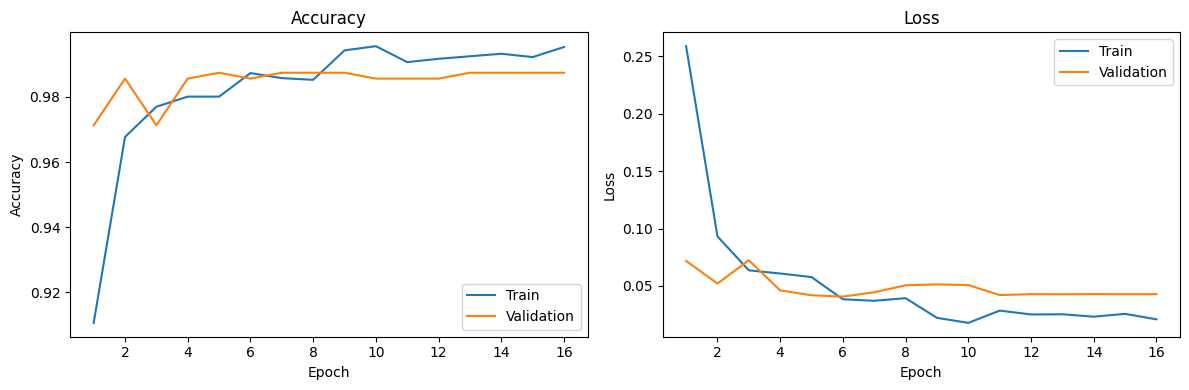

In [14]:
def combine_history(metric):
    return (history_head.history.get(metric, []) +
            history_fine.history.get(metric, []))

epochs_range = range(1, len(combine_history("accuracy")) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, combine_history("accuracy"), label="Train")
plt.plot(epochs_range, combine_history("val_accuracy"), label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, combine_history("loss"), label="Train")
plt.plot(epochs_range, combine_history("val_loss"), label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Evaluate on the held-out test set

35/35 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.9891 - loss: 0.0353
Test loss: 0.0353
Test accuracy: 98.91%
35/35 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step
\nClassification report:
              precision    recall  f1-score   support

   Flacherie     1.0000    0.9901    0.9950       203
     Healthy     0.9909    0.9954    0.9932       219
     Overlap     1.0000    0.9960    0.9980       253
     Pebrine     1.0000    0.9706    0.9851       204
   grasserie     0.9571    0.9911    0.9738       225

    accuracy                         0.9891      1104
   macro avg     0.9896    0.9887    0.9890      1104
weighted avg     0.9894    0.9891    0.9892      1104



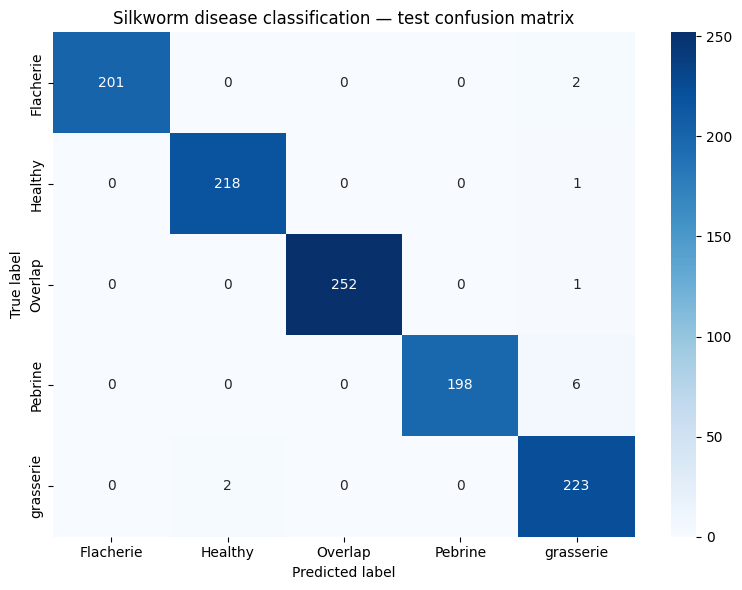

In [15]:
test_data.reset()
test_loss, test_accuracy = model.evaluate(test_data, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

test_data.reset()
probabilities = model.predict(test_data, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = test_data.classes

print("\\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Silkworm disease classification — test confusion matrix")
plt.tight_layout()
plt.show()

In [16]:

# MODEL EVALUATION METRICS TABLE

import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Generate evaluation metrics
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Convert metrics into a DataFrame
evaluation_df = pd.DataFrame(report).transpose()

# Display evaluation metrics
print("MODEL EVALUATION METRICS")
display(evaluation_df.round(4))

# Overall accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Overall Test Accuracy: {accuracy * 100:.2f}%")


MODEL EVALUATION METRICS


,precision,recall,f1-score,support
Flacherie,1.0000,0.9901,0.9950,203.0000
Healthy,0.9909,0.9954,0.9932,219.0000
Overlap,1.0000,0.9960,0.9980,253.0000
Pebrine,1.0000,0.9706,0.9851,204.0000
grasserie,0.9571,0.9911,0.9738,225.0000
accuracy,0.9891,0.9891,0.9891,0.9891
macro avg,0.9896,0.9887,0.9890,1104.0000
weighted avg,0.9894,0.9891,0.9892,1104.0000


Overall Test Accuracy: 98.91%


In [17]:

# MODEL EVALUATION METRICS TABLE

import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Generate evaluation metrics
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Convert metrics into a DataFrame
evaluation_df = pd.DataFrame(report).transpose()

# Display evaluation metrics
print("MODEL EVALUATION METRICS")
display(evaluation_df.round(4))

# Overall accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Overall Test Accuracy: {accuracy * 100:.2f}%")


MODEL EVALUATION METRICS


,precision,recall,f1-score,support
Flacherie,1.0000,0.9901,0.9950,203.0000
Healthy,0.9909,0.9954,0.9932,219.0000
Overlap,1.0000,0.9960,0.9980,253.0000
Pebrine,1.0000,0.9706,0.9851,204.0000
grasserie,0.9571,0.9911,0.9738,225.0000
accuracy,0.9891,0.9891,0.9891,0.9891
macro avg,0.9896,0.9887,0.9890,1104.0000
weighted avg,0.9894,0.9891,0.9892,1104.0000


Overall Test Accuracy: 98.91%


## 10. Save the model and class labels

In [18]:
KERAS_PATH = "/content/silkworm_disease_model.keras"
LABELS_PATH = "/content/class_labels.json"

model.save(KERAS_PATH)
with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print("Saved:", KERAS_PATH)
print("Saved:", LABELS_PATH)

Saved: /content/silkworm_disease_model.keras
Saved: /content/class_labels.json


## 11. Convert to TensorFlow Lite for hardware deployment

In [19]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

TFLITE_PATH = "/content/silkworm_disease_model.tflite"
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

print("Saved TensorFlow Lite model:", TFLITE_PATH)
print("TFLite size: {:.2f} MB".format(os.path.getsize(TFLITE_PATH) / (1024 * 1024)))

Saved artifact at '/tmp/tmpk8y1exf3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  133816548062416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548060688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548061264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548063184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548064336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548063376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548062224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548062608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548061840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133816548059920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1338165480628

## 12. Predict a new silkworm image

In [20]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

def predict_silkworm(image_path, confidence_threshold=0.60):
    image = load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
    array = img_to_array(image).astype(np.float32)
    array = np.expand_dims(array, axis=0)
    array = preprocess_input(array)

    probs = model.predict(array, verbose=0)[0]
    index = int(np.argmax(probs))
    confidence = float(probs[index])

    if confidence < confidence_threshold:
        print("Prediction is uncertain — manual inspection recommended.")
    else:
        print("Predicted class:", class_names[index])

    print(f"Model confidence: {confidence * 100:.2f}%")
    return class_names[index], confidence

# Upload a test image when prompted.
new_image = files.upload()
if new_image:
    image_path = next(iter(new_image))
    predict_silkworm(image_path)

Saving flaceria.jpg to flaceria (1).jpg
Predicted class: grasserie
Model confidence: 93.76%


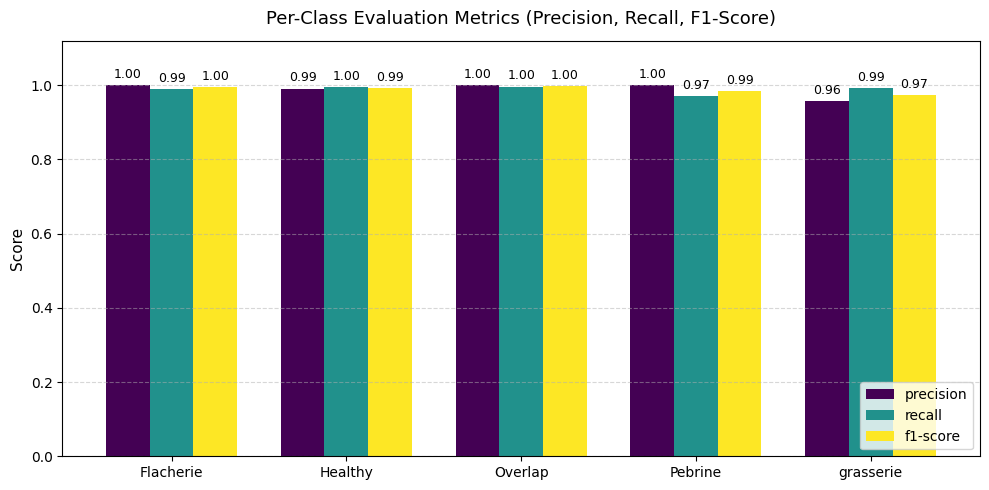

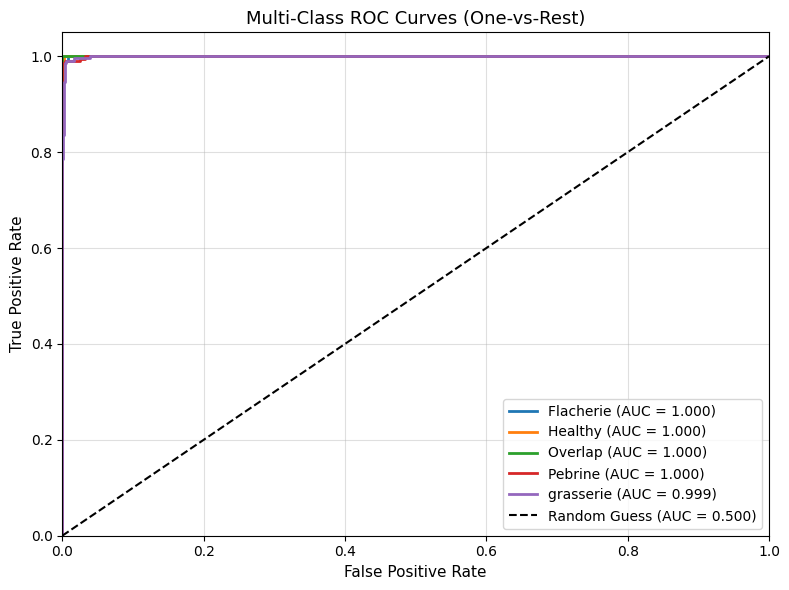

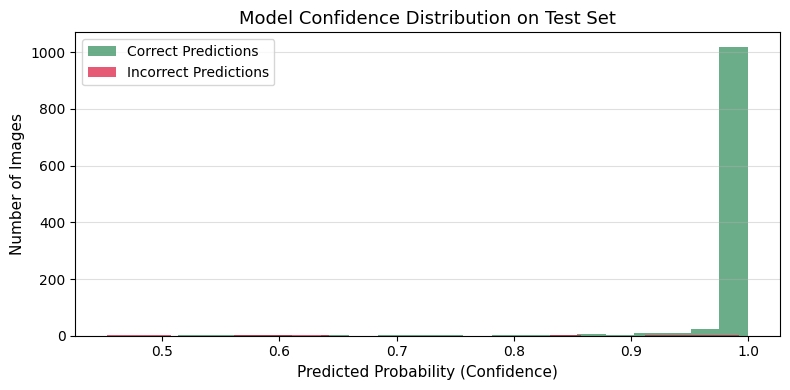

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import auc, classification_report, roc_curve
from sklearn.preprocessing import label_binarize

# 1. Per-Class Precision, Recall, and F1-Score Bar Chart
report_dict = classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
)
metrics_df = pd.DataFrame(report_dict).transpose().loc[class_names]

ax = metrics_df[['precision', 'recall', 'f1-score']].plot(
    kind='bar', figsize=(10, 5), rot=0, width=0.75, colormap='viridis'
)
plt.title(
    'Per-Class Evaluation Metrics (Precision, Recall, F1-Score)',
    fontsize=13,
    pad=12,
)
plt.ylabel('Score', fontsize=11)
plt.ylim(0, 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

# Add value labels on top of bars
for container in ax.containers:
  ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

# 2. Multi-Class ROC Curves & AUC Scores
y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
plt.figure(figsize=(8, 6))

for i, cls_name in enumerate(class_names):
  fpr, tpr, _ = roc_curve(y_true_bin[:, i], probabilities[:, i])
  roc_auc = auc(fpr, tpr)
  plt.plot(fpr, tpr, lw=2, label=f'{cls_name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('Multi-Class ROC Curves (One-vs-Rest)', fontsize=13)
plt.legend(loc='lower right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

# 3. Prediction Confidence Distribution (Correct vs. Incorrect)
max_probs = np.max(probabilities, axis=1)
correct_mask = y_pred == y_true

plt.figure(figsize=(8, 4))
plt.hist(
    max_probs[correct_mask],
    bins=20,
    alpha=0.7,
    label='Correct Predictions',
    color='seagreen',
)
plt.hist(
    max_probs[~correct_mask],
    bins=20,
    alpha=0.7,
    label='Incorrect Predictions',
    color='crimson',
)
plt.title('Model Confidence Distribution on Test Set', fontsize=13)
plt.xlabel('Predicted Probability (Confidence)', fontsize=11)
plt.ylabel('Number of Images', fontsize=11)
plt.legend()
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

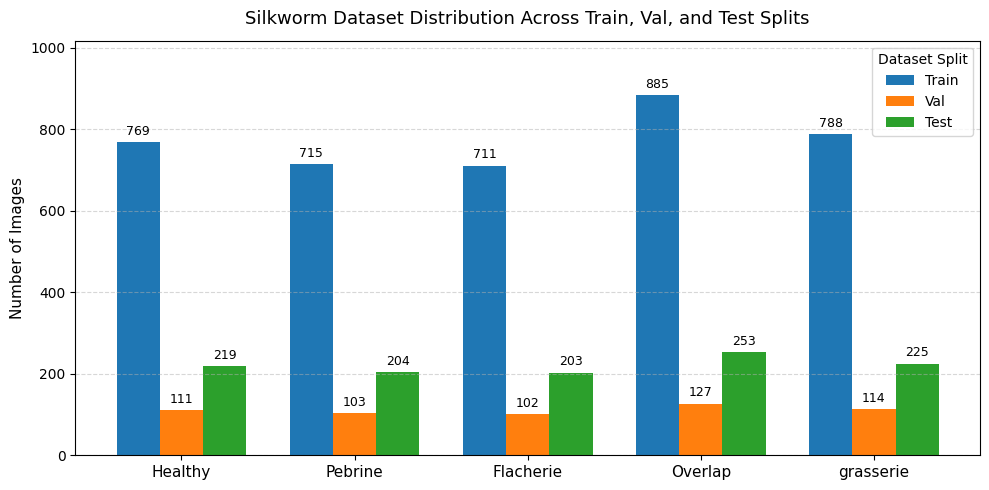

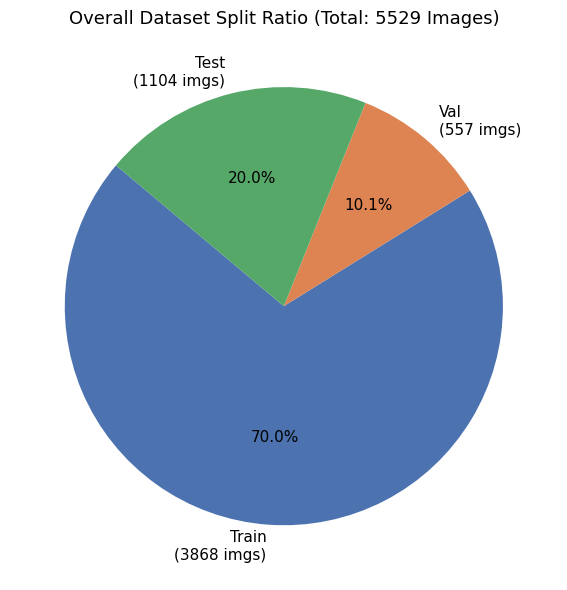

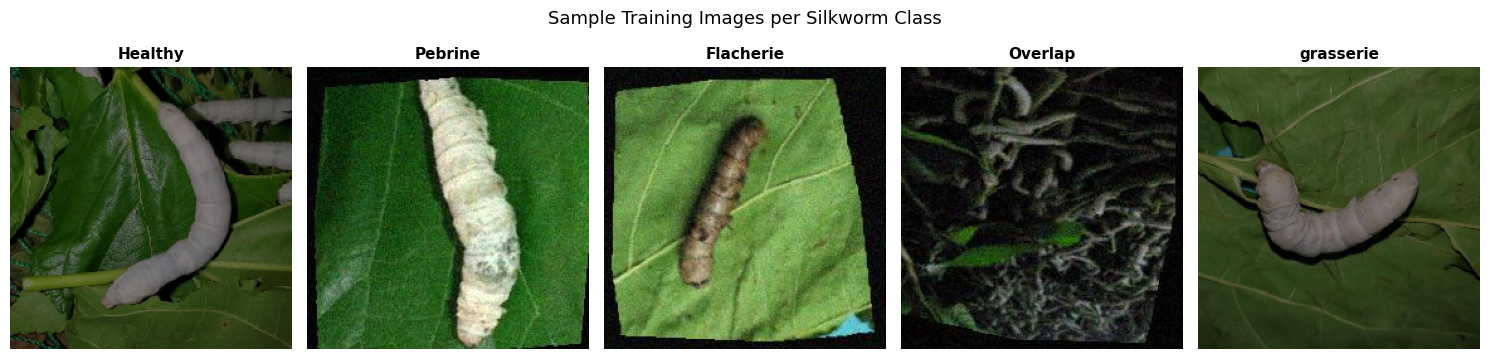

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import load_img

# 1. Grouped Bar Chart: Image Counts per Class & Split
splits = ['Train', 'Val', 'Test']
x = np.arange(len(EXPECTED_CLASSES))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

for i, split in enumerate(splits):
  split_counts = [counts[(split, cls)] for cls in EXPECTED_CLASSES]
  bars = ax.bar(x + (i - 1) * width, split_counts, width, label=split)
  ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title(
    'Silkworm Dataset Distribution Across Train, Val, and Test Splits',
    fontsize=13,
    pad=12,
)
ax.set_ylabel('Number of Images', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(EXPECTED_CLASSES, fontsize=11)
ax.set_ylim(0, max(counts.values()) * 1.15)
ax.legend(title='Dataset Split')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Pie Chart: Overall Train / Val / Test Split Ratio
split_totals = [
    sum(counts[(split, cls)] for cls in EXPECTED_CLASSES) for split in splits
]
plt.figure(figsize=(6, 6))
plt.pie(
    split_totals,
    labels=[
        f'{s}\n({t} imgs)' for s, t in zip(splits, split_totals)
    ],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4C72B0', '#DD8452', '#55A868'],
    textprops={'fontsize': 11},
)
plt.title(
    f'Overall Dataset Split Ratio (Total: {sum(split_totals)} Images)',
    fontsize=13,
)
plt.tight_layout()
plt.show()

# 3. Sample Image Grid: 1 Sample Image per Class from Training Set
fig, axes = plt.subplots(1, len(EXPECTED_CLASSES), figsize=(15, 3.5))
for ax, cls in zip(axes, EXPECTED_CLASSES):
  sample_dir = PREPARED_DIR / 'Train' / cls
  sample_file = next(sample_dir.iterdir())
  img = load_img(sample_file, target_size=(224, 224))
  ax.imshow(img)
  ax.set_title(cls, fontsize=11, fontweight='bold')
  ax.axis('off')

plt.suptitle(
    'Sample Training Images per Silkworm Class', fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()

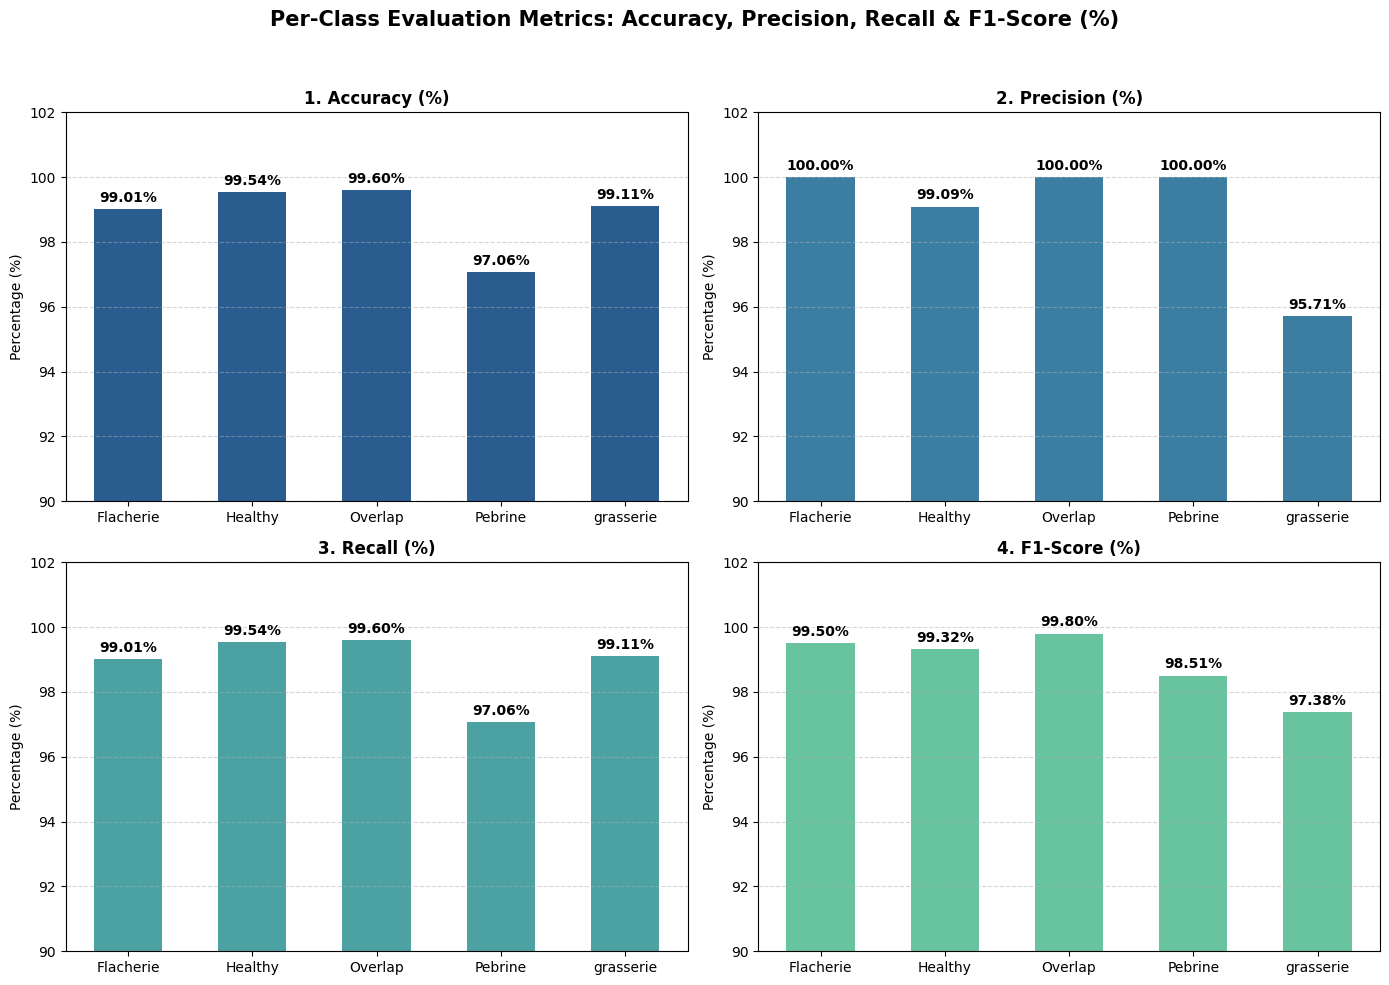

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# 1. Calculate per-class Precision, Recall, F1-Score, and Per-Class Accuracy
report_dict = classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
)
cm = confusion_matrix(y_true, y_pred)

# Per-class accuracy (True Positives / Total actual samples in that class)
per_class_acc = (cm.diagonal() / cm.sum(axis=1)) * 100
precision_vals = [report_dict[cls]['precision'] * 100 for cls in class_names]
recall_vals = [report_dict[cls]['recall'] * 100 for cls in class_names]
f1_vals = [report_dict[cls]['f1-score'] * 100 for cls in class_names]

# 2. Plot 2x2 Grid of the 4 Evaluation Metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'Per-Class Evaluation Metrics: Accuracy, Precision, Recall & F1-Score (%)',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)

metrics_data = [
    (axes[0, 0], per_class_acc, '1. Accuracy (%)', '#2b5c8f'),
    (axes[0, 1], precision_vals, '2. Precision (%)', '#3b7ea1'),
    (axes[1, 0], recall_vals, '3. Recall (%)', '#4ca1a3'),
    (axes[1, 1], f1_vals, '4. F1-Score (%)', '#68c39f'),
]

for ax, values, title, color in metrics_data:
  bars = ax.bar(class_names, values, color=color, width=0.55)
  ax.set_title(title, fontsize=12, fontweight='bold')
  ax.set_ylabel('Percentage (%)')
  ax.set_ylim(90, 102)  # Zoomed to clearly show differences between 95%–100%
  ax.grid(axis='y', linestyle='--', alpha=0.5)
  ax.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=10, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('silkworm_4_metrics_grid.png', dpi=300, bbox_inches='tight')
plt.show()

## 13. Download the deployment files

In [ ]:
from google.colab import files

files.download(TFLITE_PATH)
files.download(KERAS_PATH)
files.download(LABELS_PATH)

## Notes for your hardware integration

- The `.tflite` model expects an RGB image resized to **224 × 224** and normalized using `(pixel / 127.5) - 1`.
- The output is a 5-element softmax probability vector. Use `class_labels.json` to map the output index to a class name.
- This model classifies **images only**. DHT11 temperature/humidity, LDR and moisture readings are separate sensor inputs; they are not used by this image classifier.
- A confidence score is not proof of disease. Validate using images captured by your actual camera, under different lighting and distance conditions, before relying on predictions.
- The dataset split is retained. Do not use the test set to tune hyperparameters; keep it for final evaluation.
